# Week 3: Rain and bakery turnover

I wanted to check whether the bakery sells fewer Rolls on days when the weather data records precipitation.

**Hypothesis:** Rolls turnover is lower on dates with a precipitation code, even after accounting for weekday, month, year, temperature, and Kiel Week.

A simple comparison might be misleading because sales also change by season and weekday. I compare the raw averages first, then use a regression to account for some of those differences.

In the prepared data, `precipitation = 1` means the weather code was between 50 and 99. A value of `0` means it was not coded as precipitation; this also includes missing weather codes, so it does not always mean the day was dry. The weather is observed rather than forecast, and this analysis can show an association but not prove that rain caused a change in sales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = ["Bread", "Rolls", "Croissants", "Confectionery", "Cakes", "Seasonal bread"]
data = pd.read_csv("../0_DataPreparation/prepared_data.csv", parse_dates=["Datum"])
data = data.loc[data["set"] == "train"].copy().sort_values(["product_group", "Datum"])

required_columns = {
    "id", "Datum", "product_group", "Umsatz", "weekday", "month",
    "KielerWoche", "is_holiday", "day_before_holiday", "christmas_eve",
    "new_years_eve", "Temperatur", "precipitation",
}
assert required_columns.issubset(data.columns), "Prepared data is missing a required column"
assert len(data) == 9334, "Training row count differs from the documented sales data"
assert data["id"].is_unique, "Training data contains a duplicate row ID"
assert data["precipitation"].notna().all(), "Precipitation contains missing values"
assert set(data["precipitation"].unique()).issubset({0, 1}), "Precipitation must be coded as 0 or 1"
assert (data["Umsatz"] > 0).all(), "Training turnover must be positive"
assert not data.duplicated(["Datum", "product_group"]).any(), "Duplicate date and product-group rows found"
assert data["product_group"].isin(GROUPS).all(), "Unexpected product group found"

rolls = data.loc[data["product_group"] == "Rolls"].copy()
assert not rolls.empty, "No Rolls rows found in the training data"
assert set(rolls["precipitation"].unique()) == {0, 1}, "Both precipitation categories are needed for Rolls"
rolls["weekday"] = pd.Categorical(rolls["weekday"], categories=WEEKDAYS, ordered=True)
data["weekday"] = pd.Categorical(data["weekday"], categories=WEEKDAYS, ordered=True)
data["year"] = data["Datum"].dt.year
data["log_turnover"] = np.log(data["Umsatz"])

print(f"Training rows: {len(data):,}")
print(f"Period: {data['Datum'].min().date()} to {data['Datum'].max().date()}")
print(f"Rolls rows: {len(rolls):,}")

Training rows: 9,334
Period: 2013-07-01 to 2018-07-31
Rolls rows: 1,819


## 1. How often is precipitation recorded in the training data?

Each product row for a date has the same precipitation value, so I keep one value per date for this count. This also checks that the values agree across products. These are dates with sales records, not every calendar day; dates with no recorded sales are not included.

Dates with a precipitation code: 643 of 1819 dates with sales (35%)


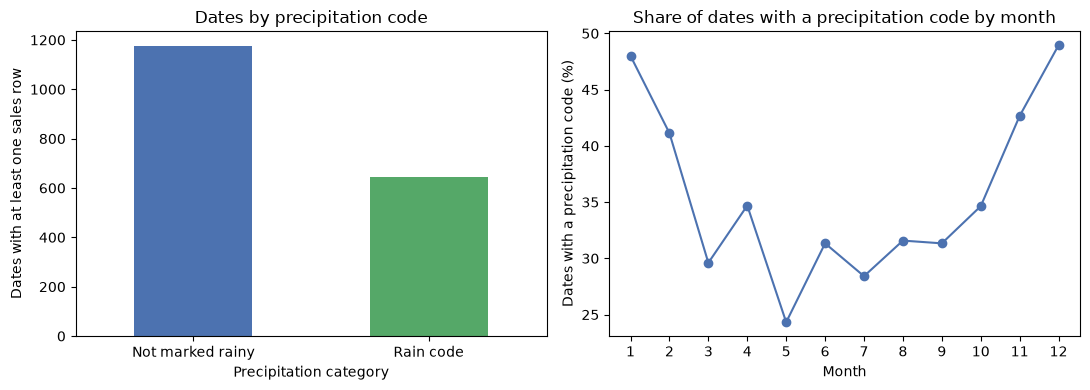

In [2]:
daily_rain = data.groupby("Datum")["precipitation"].agg(["first", "nunique"])
assert daily_rain["nunique"].eq(1).all(), "Product rows disagree on daily precipitation"
daily_rain = daily_rain["first"].rename("precipitation").to_frame()
daily_rain["month"] = daily_rain.index.month
rainy_days = int(daily_rain["precipitation"].sum())
print(f"Dates with a precipitation code: {rainy_days} of {len(daily_rain)} dates with sales ({daily_rain['precipitation'].mean():.0%})")

monthly_rain = daily_rain.groupby("month")["precipitation"].mean().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
daily_rain["precipitation"].value_counts().reindex([0, 1], fill_value=0).rename(
    index={0: "Not marked rainy", 1: "Rain code"}
).plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#55A868"]
)
axes[0].set_title("Dates by precipitation code")
axes[0].set_xlabel("Precipitation category")
axes[0].set_ylabel("Dates with at least one sales row")
axes[0].tick_params(axis="x", rotation=0)
axes[1].plot(monthly_rain.index, monthly_rain.values, marker="o", color="#4C72B0")
axes[1].set_title("Share of dates with a precipitation code by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Dates with a precipitation code (%)")
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

## 2. First look: dates coded with precipitation versus other dates

Here I compare average turnover for each product group. The percentage is just the difference between the two averages; it does not account for weekday, month, or temperature. Missing weather codes are included with dates not marked as precipitation, following the project decision.

precipitation,not marked rainy,rain code,difference %
product_group,,,
Bread,124.1,118.5,-4.5
Rolls,411.1,386.8,-5.9
Croissants,169.1,152.7,-9.7
Confectionery,88.0,87.8,-0.2
Cakes,279.0,272.8,-2.2
Seasonal bread,67.2,66.6,-1.0


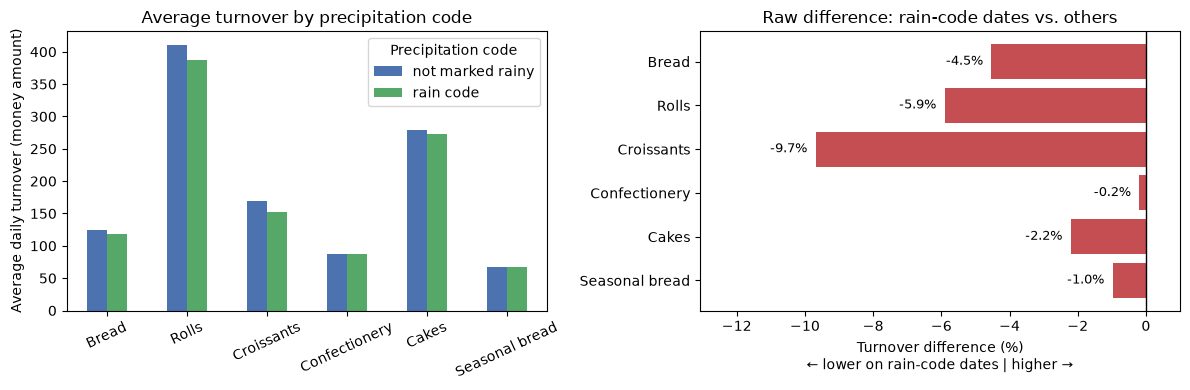

In [3]:
raw = data.groupby(["product_group", "precipitation"])["Umsatz"].mean().unstack()
raw = raw.rename(columns={0: "not marked rainy", 1: "rain code"}).reindex(GROUPS)
raw["difference %"] = (raw["rain code"] / raw["not marked rainy"] - 1).mul(100)
display(raw.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw[["not marked rainy", "rain code"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#55A868"])
axes[0].set_title("Average turnover by precipitation code")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average daily turnover (money amount)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Precipitation code")
raw["difference %"].plot(kind="bar", ax=axes[1], color="#8172B2")
axes[1].axhline(0, color="black", linewidth=1)
differences = raw["difference %"].reindex(GROUPS)
colors = ["#C44E52" if value < 0 else "#55A868" for value in differences]
axes[1].clear()
axes[1].barh(GROUPS, differences, color=colors)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Raw difference: rain-code dates vs. others")
axes[1].set_xlabel("Turnover difference (%)\n← lower on rain-code dates | higher →")
axes[1].set_ylabel("")
axes[1].invert_yaxis()
axes[1].set_xlim(min(differences.min() * 1.35, -1), max(differences.max() * 1.35, 1))
for position, value in enumerate(differences):
    axes[1].text(
        value - 0.25 if value < 0 else value + 0.25,
        position,
        f"{value:+.1f}%",
        va="center",
        ha="right" if value < 0 else "left",
        fontsize=9,
    )
plt.tight_layout()
plt.show()

## 3. Fair comparison: control for calendar and temperature

To make the comparison fairer, I use a regression that holds weekday, month, year, Kiel Week, holidays, the day before a holiday, Christmas Eve, and New Year's Eve constant. Model B also holds temperature constant. The results are shown as percentage differences in turnover. Some product groups do not have every kind of holiday in the data, so a holiday variable is left out when it never changes for that group. The standard errors allow nearby observations to be related; because some dates are missing, seven observations are not always seven calendar days.

Model A adjusts for the calendar factors but not temperature. Model B also includes temperature and is the main test of my hypothesis.

If the 95% confidence interval includes zero, the data do not clearly show a difference.

In [4]:
def fit_rain_model(group, include_temperature):
    subset = data.loc[data["product_group"] == group].copy()
    flags = [
        column for column in [
            "KielerWoche", "is_holiday", "day_before_holiday", "christmas_eve", "new_years_eve"
        ]
        if subset[column].nunique() > 1
    ]
    controls = ["C(weekday)", "C(month)", "C(year)"] + flags
    formula = "log_turnover ~ precipitation + " + " + ".join(controls)
    if include_temperature:
        formula += " + Temperatur"
    fitted = smf.ols(formula, data=subset).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    coefficient = fitted.params["precipitation"]
    ci_low, ci_high = fitted.conf_int().loc["precipitation"]
    to_percent = lambda value: np.expm1(value) * 100
    return {
        "product group": group,
        "rows": int(fitted.nobs),
        "rain-code rows": int(subset["precipitation"].sum()),
        "adjusted difference %": to_percent(coefficient),
        "95% low %": to_percent(ci_low),
        "95% high %": to_percent(ci_high),
        "p-value": fitted.pvalues["precipitation"],
    }

results = {}
for label, include_temperature in [("A: without temperature", False), ("B: with temperature", True)]:
    results[label] = pd.DataFrame(
        [fit_rain_model(group, include_temperature) for group in GROUPS]
    ).set_index("product group")
    print(label)
    print(results[label].round({"adjusted difference %": 1, "95% low %": 1, "95% high %": 1, "p-value": 3}).to_string())
    print()

A: without temperature
                rows  rain-code rows  adjusted difference %  95% low %  95% high %  p-value
product group                                                                              
Bread           1819             643                   -4.8       -6.9        -2.6    0.000
Rolls           1819             643                   -2.1       -3.7        -0.5    0.010
Croissants      1819             643                   -4.1       -6.3        -1.7    0.001
Confectionery   1766             624                   -0.4       -3.0         2.3    0.777
Cakes           1819             643                   -1.8       -3.5        -0.1    0.040
Seasonal bread   292             132                   -5.4      -15.8         6.1    0.342

B: with temperature
                rows  rain-code rows  adjusted difference %  95% low %  95% high %  p-value
product group                                                                              
Bread           1819             643

## 4. Plot the adjusted results

The dots show the Model B estimates and the lines show their 95% confidence intervals. The dashed line marks zero difference. When a confidence interval crosses that line, the result is uncertain.

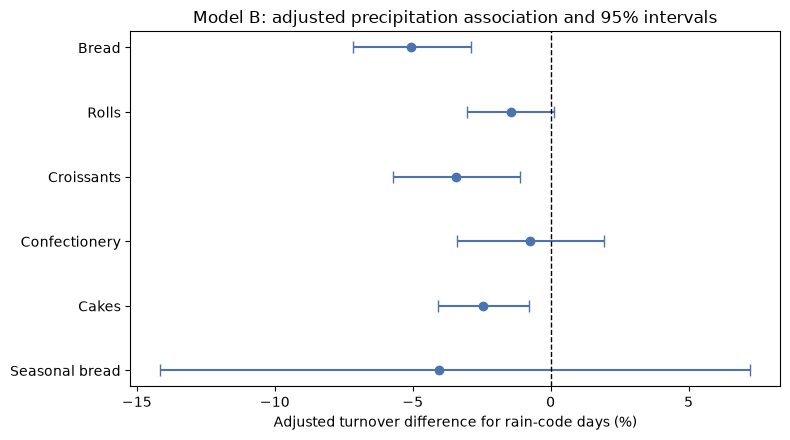

In [5]:
model_b = results["B: with temperature"].reindex(GROUPS)
positions = np.arange(len(GROUPS))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    model_b["adjusted difference %"],
    positions,
    xerr=[
        model_b["adjusted difference %"] - model_b["95% low %"],
        model_b["95% high %"] - model_b["adjusted difference %"],
    ],
    fmt="o",
    capsize=4,
    color="#4C72B0",
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(positions, GROUPS)
ax.invert_yaxis()
ax.set_xlabel("Adjusted turnover difference for rain-code days (%)")
ax.set_title("Model B: adjusted precipitation association and 95% intervals")
plt.tight_layout()
plt.show()

## 5. Conclusion

For Rolls, Model A estimates a **2.1% decrease** on dates with a precipitation code (95% interval: **−3.7% to −0.5%**). After adding temperature in Model B, the estimate is a **1.5% decrease** (95% interval: **−3.0% to +0.1%**). Because this interval includes zero, the results do not clearly support my hypothesis once temperature is included. The other product groups are included for context, so their results should be treated as exploratory.

This is an association in past sales and observed weather. It does not show that rain caused the difference, and a weather forecast may be less accurate than the observed weather used here.